In [47]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [48]:
# Download all libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.gridspec import GridSpec

# Explicitly point to the cache folder inside your Data3001 project directory
CACHE = Path.home() / "Desktop" / "Data3001" / "cache"
EXTRACT = CACHE / "humboldt_obs.npz"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

VARS = ["lon", "lat", "time", "ve", "vn", "sst"]
if not EXTRACT.exists() and not all((CACHE / f"{v}.npy").exists() for v in VARS + ["rowsize", "id"]):
    from clouddrift.datasets import gdp1h
    CACHE.mkdir(exist_ok=True)
    ds = gdp1h()
    for v in VARS + ["rowsize", "id"]:
        np.save(CACHE / f"{v}.npy", ds[v].values)

# Selected region: Humboldt Region. Study time: 2001 to 2022
R = dict(lon=(-89, -65), lat=(-49, -4))
START, END = np.datetime64("2001-01-01", "ns"), np.datetime64("2023-01-01", "ns")


def build_extract(chunk=2_000_000):
    """Keep valid SST and velocity observations in the study region and period.

    The global arrays need more memory than this laptop has, so they are read from disk
    in chunks. This runs once; later runs load the small extract file.
    """
    raw = {v: np.load(CACHE / f"{v}.npy", mmap_mode="r") for v in VARS}
    ids = np.load(CACHE / "id.npy")
    last_row = np.cumsum(np.load(CACHE / "rowsize.npy"))
    parts = {k: [] for k in ["id", "time", "lon", "lat", "sst", "ve", "vn"]}
    for a in range(0, len(raw["lon"]), chunk):
        b = a + chunk
        lon, lat = np.asarray(raw["lon"][a:b]), np.asarray(raw["lat"][a:b])
        rows = np.flatnonzero((lon >= R["lon"][0]) & (lon <= R["lon"][1])
                              & (lat >= R["lat"][0]) & (lat <= R["lat"][1]))
        if len(rows) == 0:
            continue
        t = np.asarray(raw["time"][a:b])[rows]
        sst, ve, vn = (np.asarray(raw[v][a:b])[rows] for v in ["sst", "ve", "vn"])
        good = (t >= START) & (t < END) & np.isfinite(sst) & np.isfinite(ve) & np.isfinite(vn)
        rows = rows[good]
        parts["id"].append(ids[np.searchsorted(last_row, a + rows, side="right")])
        parts["time"].append(t[good])
        parts["lon"].append(lon[rows])
        parts["lat"].append(lat[rows])
        parts["sst"].append(sst[good])
        parts["ve"].append(ve[good])
        parts["vn"].append(vn[good])
    np.savez(EXTRACT, **{k: np.concatenate(v) for k, v in parts.items()})


if not EXTRACT.exists():
    build_extract()


In [49]:
print("Applying filters to local cache...")

# 1. Assemble the clean DataFrame from the regional extract
obs = np.load(EXTRACT)
df = pd.DataFrame({
    "id": obs["id"],
    "time": obs["time"],
    "lon": obs["lon"],
    "lat": obs["lat"],
    "sst_degC": obs["sst"] - 273.15,  # Convert SST from Kelvin to Celsius
    "ve": obs["ve"],
    "vn": obs["vn"],
})

# 2. Calculate the overall speed using sqrt(ve^2 + vn^2)
df["speed"] = np.hypot(df["ve"], df["vn"])

# 3. Add time groupings and apply the physical sanity check we discussed earlier
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["doy"] = df["time"].dt.dayofyear
# 5 C floor: real winter SST south of 40S falls below 10 C, but values outside this range are sensor errors
df = df[(df["sst_degC"] >= 5.0) & (df["sst_degC"] <= 35.0)]
# Remove readings east of the Andes: these are in the Atlantic, not the Humboldt system
df = df[~((df["lat"] < -40) & (df["lon"] > -71))].reset_index(drop=True)

print(f"\nSuccessfully loaded {len(df):,} valid observations.")
print(df.head())


Applying filters to local cache...

Successfully loaded 2,537,111 valid observations.
      id                time        lon        lat   sst_degC      ve      vn     speed  year  month  doy
0  29327 2003-10-07 14:00:00 -88.997658 -34.694439  14.248993  0.1575  0.2020  0.256145  2003     10  280
1  29327 2003-10-07 15:00:00 -88.991379 -34.688568  14.268005  0.1552  0.2016  0.254420  2003     10  280
2  29327 2003-10-07 16:00:00 -88.986092 -34.679878  14.287994  0.1345  0.2642  0.296466  2003     10  280
3  29327 2003-10-07 17:00:00 -88.980850 -34.671059  14.307007  0.1594  0.3087  0.347425  2003     10  280
4  29327 2003-10-07 18:00:00 -88.973770 -34.660419  14.329010  0.1637  0.3122  0.352515  2003     10  280


In [50]:
# ============================================================================
# LOCATION-CORRECTED MONTHLY SST ANOMALIES
# Place this directly after the cell that builds `df`.
# Needs numpy, pandas and scipy 1.8 or newer.
#
# THE PROBLEM
# Drifters are not spread evenly, and the south of the region is much colder
# than the north. A month with more southern drifters therefore looks cold even
# if the ocean has not changed. The simple monthly mean has a 0.92 correlation
# with the drifters' mean latitude, so it mostly tracks where they were.
#
# THE FIX
# Compare each reading with what is normal for that place and time of year,
# then average those differences (anomalies) instead of the raw temperatures.
#
# WHAT THIS CELL CREATES
# In df (one row per hourly reading):
#   sst_baseline    normal SST for that location and day of year (C)
#   sst_anom        sst_degC minus sst_baseline (C)
#
# In sst_monthly (one row per month, 2001 to 2022):
#   sst_anom        regional anomaly, the main corrected series (C)
#   sst_anom_north  anomaly north of 30S (C)
#   sst_anom_south  anomaly south of 30S (C)
#   sst_adjusted    regional normal for that calendar month plus sst_anom (C)
#   sst_simple      uncorrected monthly mean, kept for comparison (C)
#   mean_lat        mean latitude of that month's readings
#   n_drifters      number of drifters in the month
#   n_cells         number of 2-degree cells used in the month
#   low_coverage    True if under 10 cells or under 5 drifters; treat with care
#   date            15th of the month, for plotting
# ============================================================================
from scipy.interpolate import BSpline

# ---- Step 1: filters --------------------------------------------------------
# Real winter SST south of 40S falls below 10 C, so a 10 C minimum makes the far
# south look about 1.9 C too warm. If df was built with that minimum, start again
# from the clean arrays so those cold readings return.
if "clean_sst" in globals():
    df = pd.DataFrame({"id": clean_ids, "time": clean_time, "lon": clean_lon, "lat": clean_lat,
                       "sst_degC": clean_sst, "ve": clean_ve, "vn": clean_vn, "speed": clean_speed})
    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month

df["doy"] = df["time"].dt.dayofyear
df = df[(df["sst_degC"] >= 5.0) & (df["sst_degC"] <= 35.0)]
# The region's box also catches the Atlantic east of the Andes, which is not part of the Humboldt system
df = df[~((df["lat"] < -40) & (df["lon"] > -71))].reset_index(drop=True)

# ---- Step 2: the baseline model ---------------------------------------------
# SST(lat, lon, day of year) = smooth map + smooth maps of the annual and
# semi-annual cycles. A smooth fit is needed because many 1-degree cells, mainly
# in the north, have only a few drifters and do not cover every calendar month.
LAT_SPLINE = (-49, -4, 16)   # (min, max, number of basis functions)
LON_SPLINE = (-89, -65, 10)
SMOOTHING = 1.0              # larger values give a smoother map
N_HARMONICS = 2              # 1 = annual cycle, 2 = adds the semi-annual cycle


def spline_basis(x, lo, hi, n, degree=3):
    """Smooth curves along one axis, which combine to form the map."""
    inner = np.linspace(lo, hi, n - degree + 1)
    knots = np.r_[[lo] * degree, inner, [hi] * degree]
    return BSpline.design_matrix(np.clip(x, lo, hi - 1e-9), knots, degree).toarray()


def seasonal_terms(doy):
    """Constant term plus sine and cosine waves for each seasonal cycle."""
    w = 2 * np.pi * doy / 365.25
    terms = [np.ones_like(w)]
    for k in range(1, N_HARMONICS + 1):
        terms += [np.cos(k * w), np.sin(k * w)]
    return np.column_stack(terms)


def design_matrix(lat, lon, doy):
    """Combine latitude, longitude and season so each season gets its own map."""
    A, B, H = spline_basis(lat, *LAT_SPLINE), spline_basis(lon, *LON_SPLINE), seasonal_terms(doy)
    surface = (A[:, :, None] * B[:, None, :]).reshape(len(lat), -1)
    return (H[:, :, None] * surface[:, None, :]).reshape(len(lat), -1)


def roughness_penalty():
    """Penalise sharp changes between neighbouring map points."""
    D = lambda n: np.diff(np.eye(n), 2, axis=0)
    na, nb = LAT_SPLINE[2], LON_SPLINE[2]
    spatial = (np.kron(D(na).T @ D(na), np.eye(nb))
               + np.kron(np.eye(na), D(nb).T @ D(nb)))
    return np.kron(np.eye(1 + 2 * N_HARMONICS), spatial)


def predict(beta, lat, lon, doy, chunk=20_000):
    """Normal SST for any set of points, in chunks to keep memory use low."""
    out = np.empty(len(lat))
    for i in range(0, len(lat), chunk):
        s = slice(i, i + chunk)
        out[s] = design_matrix(lat[s], lon[s], doy[s]) @ beta
    return out


# ---- Step 3: fit the baseline -----------------------------------------------
# Fit to 1-degree cell monthly averages, so a drifter's many hourly readings do
# not dominate. Each year gets equal total weight, so data-rich years do not
# define what is normal.
units = (df.assign(cell_lat=np.floor(df["lat"]), cell_lon=np.floor(df["lon"]))
           .groupby(["cell_lat", "cell_lon", "year", "month"])
           .agg(lat=("lat", "mean"), lon=("lon", "mean"), doy=("doy", "mean"), sst=("sst_degC", "mean"))
           .reset_index())
unit_weight = (1 / units.groupby("year")["sst"].transform("size")).to_numpy()
unit_weight = unit_weight * len(units) / unit_weight.sum()

# Build the fit one year at a time, so the full matrix never sits in memory
XtWX_year, XtWy_year = {}, {}
for year in sorted(units["year"].unique()):
    k = (units["year"] == year).to_numpy()
    Xk = design_matrix(units["lat"].to_numpy()[k], units["lon"].to_numpy()[k], units["doy"].to_numpy()[k])
    XtWX_year[year] = (Xk.T * unit_weight[k]) @ Xk
    XtWy_year[year] = (Xk.T * unit_weight[k]) @ units["sst"].to_numpy()[k]
XtWX, XtWy = sum(XtWX_year.values()), sum(XtWy_year.values())
penalty = SMOOTHING * roughness_penalty() + 1e-6 * np.eye(XtWX.shape[0])

# Fit using all years; used only for the regional normal in Step 6
beta_full = np.linalg.solve(XtWX + penalty, XtWy)

# ---- Step 4: anomaly for each reading ---------------------------------------
# Each year is compared with a baseline fitted WITHOUT that year. Otherwise an
# unusual year would shift its own definition of normal and hide part of its signal.
df["sst_baseline"] = np.nan
for year, rows in df.groupby("year").indices.items():
    beta = np.linalg.solve(XtWX - XtWX_year[year] + penalty, XtWy - XtWy_year[year])
    df.iloc[rows, df.columns.get_loc("sst_baseline")] = predict(
        beta, df["lat"].to_numpy()[rows], df["lon"].to_numpy()[rows], df["doy"].to_numpy()[rows].astype(float))
df["sst_anom"] = df["sst_degC"] - df["sst_baseline"]

# ---- Step 5: combine anomalies into monthly series --------------------------
# Average within 2-degree cells first, so a cluster of drifters counts as one
# location. Then average the cells, weighted by area, as cells shrink further south.
CELL_DEG = 2
MIN_READINGS = 24        # a cell needs about one drifter-day of readings in the month
NORTH_SOUTH_SPLIT = -30

cells = df.assign(cell_lat=np.floor(df["lat"] / CELL_DEG) * CELL_DEG,
                  cell_lon=np.floor(df["lon"] / CELL_DEG) * CELL_DEG)
cell_month = (cells.groupby(["year", "month", "cell_lat", "cell_lon"])["sst_anom"]
                   .agg(anom="mean", n="size").reset_index())
cell_month = cell_month[cell_month["n"] >= MIN_READINGS]
cell_month["centre_lat"] = cell_month["cell_lat"] + CELL_DEG / 2
cell_month["area"] = np.cos(np.radians(cell_month["centre_lat"]))


def area_mean(c):
    """Area-weighted mean of the cell anomalies for each month."""
    keys = [c["year"], c["month"]]
    return (c["anom"] * c["area"]).groupby(keys).sum() / c["area"].groupby(keys).sum()


all_months = pd.MultiIndex.from_product([range(2001, 2023), range(1, 13)], names=["year", "month"])
north = cell_month["centre_lat"] >= NORTH_SOUTH_SPLIT
sst_monthly = pd.DataFrame({
    "sst_anom": area_mean(cell_month),
    "sst_anom_north": area_mean(cell_month[north]),
    "sst_anom_south": area_mean(cell_month[~north]),
}).reindex(all_months)

by_month = df.groupby(["year", "month"])
sst_monthly["n_drifters"] = by_month["id"].nunique()
sst_monthly["n_cells"] = cell_month.groupby(["year", "month"]).size()
sst_monthly[["n_drifters", "n_cells"]] = sst_monthly[["n_drifters", "n_cells"]].fillna(0).astype(int)
sst_monthly["low_coverage"] = (sst_monthly["n_cells"] < 10) | (sst_monthly["n_drifters"] < 5)

# ---- Step 6: convert back to a temperature ----------------------------------
# sst_adjusted = the region's normal SST for that calendar month + sst_anom.
# The normal always uses the same fixed cells, so it cannot move with the drifters.
fixed_cells = (cells.groupby(["cell_lat", "cell_lon"])
                    .agg(lat=("lat", "mean"), lon=("lon", "mean")).reset_index())
fixed_area = np.cos(np.radians(fixed_cells["cell_lat"] + CELL_DEG / 2))
mid_month_doy = pd.date_range("2001-01-15", periods=12, freq=pd.DateOffset(months=1)).dayofyear.to_numpy(float)
regional_normal = pd.Series(
    [np.average(predict(beta_full, fixed_cells["lat"].to_numpy(), fixed_cells["lon"].to_numpy(),
                        np.full(len(fixed_cells), d)), weights=fixed_area) for d in mid_month_doy],
    index=pd.RangeIndex(1, 13, name="month"))
sst_monthly["sst_adjusted"] = sst_monthly.index.get_level_values("month").map(regional_normal) + sst_monthly["sst_anom"]

# Uncorrected values, kept for comparison
sst_monthly["sst_simple"] = by_month["sst_degC"].mean()
sst_monthly["mean_lat"] = by_month["lat"].mean()
sst_monthly["date"] = pd.to_datetime({"year": sst_monthly.index.get_level_values("year"),
                                      "month": sst_monthly.index.get_level_values("month"),
                                      "day": 15}).to_numpy()

print(f"Readings used: {len(df):,}")
print(f"Months with data: {sst_monthly['sst_anom'].notna().sum()} of {len(sst_monthly)}; "
      f"low coverage: {(sst_monthly['low_coverage'] & sst_monthly['sst_anom'].notna()).sum()}")
sst_monthly.head()


Readings used: 2,537,111
Months with data: 260 of 264; low coverage: 34


sst_anom  sst_anom_north  sst_anom_south  n_drifters  n_cells  low_coverage  sst_adjusted  sst_simple   mean_lat       date
year month                                                                                                                             
2001 1           NaN             NaN             NaN           0        0          True           NaN         NaN        NaN 2001-01-15
     2           NaN             NaN             NaN           0        0          True           NaN         NaN        NaN 2001-02-15
     3     -0.049082       -0.049082             NaN           4        7          True     20.621028   21.551176 -23.691823 2001-03-15
     4      0.189637        0.189637             NaN           4        9          True     20.019799   21.112400 -24.204014 2001-04-15
     5     -0.435273       -0.331453       -0.609888           4        9          True     18.138975   17.605419 -28.360858 2001-05-15

In [51]:
# Checks: has the sampling bias gone, and how do the series relate to ONI?
oni = pd.read_csv("oni.ascii.txt", sep=r"\s+")
season_centre = dict(zip("DJF JFM FMA MAM AMJ MJJ JJA JAS ASO SON OND NDJ".split(), range(1, 13)))
oni["month"] = oni["SEAS"].map(season_centre)
sst_monthly["oni"] = oni.set_index(["YR", "month"])["ANOM"].rename_axis(["year", "month"]).reindex(sst_monthly.index)

calendar_month = sst_monthly.index.get_level_values("month")
deseason = lambda s: s - s.groupby(calendar_month).transform("mean")
lat_anom = deseason(sst_monthly["mean_lat"])
compared = {"Simple mean": deseason(sst_monthly["sst_simple"]),
            "sst_anom": sst_monthly["sst_anom"],
            "sst_anom_north": sst_monthly["sst_anom_north"],
            "sst_anom_south": sst_monthly["sst_anom_south"]}

# oni.shift(-4) pairs each month with ONI four months later (SST leading ONI)
checks = pd.DataFrame({name: {"Std dev (C)": s.std(),
                              "Corr with drifter latitude": s.corr(lat_anom),
                              "Corr with ONI, same month": s.corr(sst_monthly["oni"]),
                              "Corr with ONI 4 months later": s.corr(sst_monthly["oni"].shift(-4))}
                       for name, s in compared.items()}).T
checks.round(2)


,Std dev (C),Corr with drifter latitude,"Corr with ONI, same month",Corr with ONI 4 months later
Simple mean,1.76,0.92,0.11,0.08
sst_anom,0.45,0.06,0.17,0.28
sst_anom_north,0.54,0.04,0.27,0.34
sst_anom_south,0.49,0.12,0.00,0.15


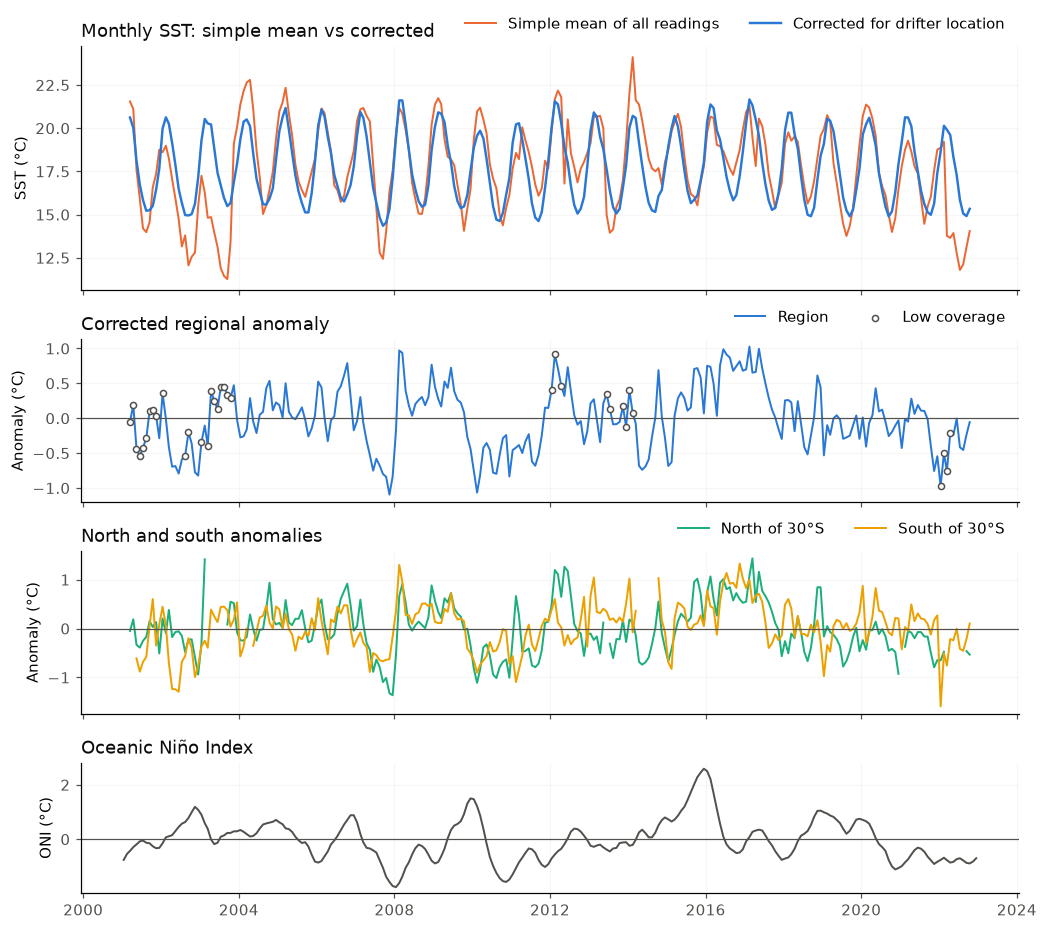

In [52]:
# Figure: the simple mean against the corrected series, with ONI on its own panel
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
m = sst_monthly

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True,
                         gridspec_kw={"height_ratios": [1.5, 1, 1, 0.8], "hspace": 0.28})
ax = axes[0]
ax.plot(m["date"], m["sst_simple"], color=ORANGE, lw=1.3, label="Simple mean of all readings")
ax.plot(m["date"], m["sst_adjusted"], color=BLUE, lw=1.6, label="Corrected for drifter location")
ax.set_ylabel("SST (°C)")
ax.set_title("Monthly SST: simple mean vs corrected", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)

ax = axes[1]
ax.plot(m["date"], m["sst_anom"], color=BLUE, lw=1.3, label="Region")
low = m[m["low_coverage"]]
ax.scatter(low["date"], low["sst_anom"], s=16, facecolors="white", edgecolors=MUTED, linewidths=1,
           zorder=3, label="Low coverage")
ax.set_ylabel("Anomaly (°C)")
ax.set_title("Corrected regional anomaly", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)

ax = axes[2]
ax.plot(m["date"], m["sst_anom_north"], color=AQUA, lw=1.3, label=f"North of {abs(NORTH_SOUTH_SPLIT)}°S")
ax.plot(m["date"], m["sst_anom_south"], color=YELLOW, lw=1.3, label=f"South of {abs(NORTH_SOUTH_SPLIT)}°S")
ax.set_ylabel("Anomaly (°C)")
ax.set_title("North and south anomalies", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)

ax = axes[3]
ax.plot(m["date"], m["oni"], color=MUTED, lw=1.3)
ax.set_ylabel("ONI (°C)")
ax.set_title("Oceanic Niño Index", loc="left", color=INK)

for ax in axes:
    ax.grid(True, color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
for ax in axes[1:]:
    ax.axhline(0, color=MUTED, lw=0.8)
plt.show()


Correlation 0.967; RMS difference 1.02 C


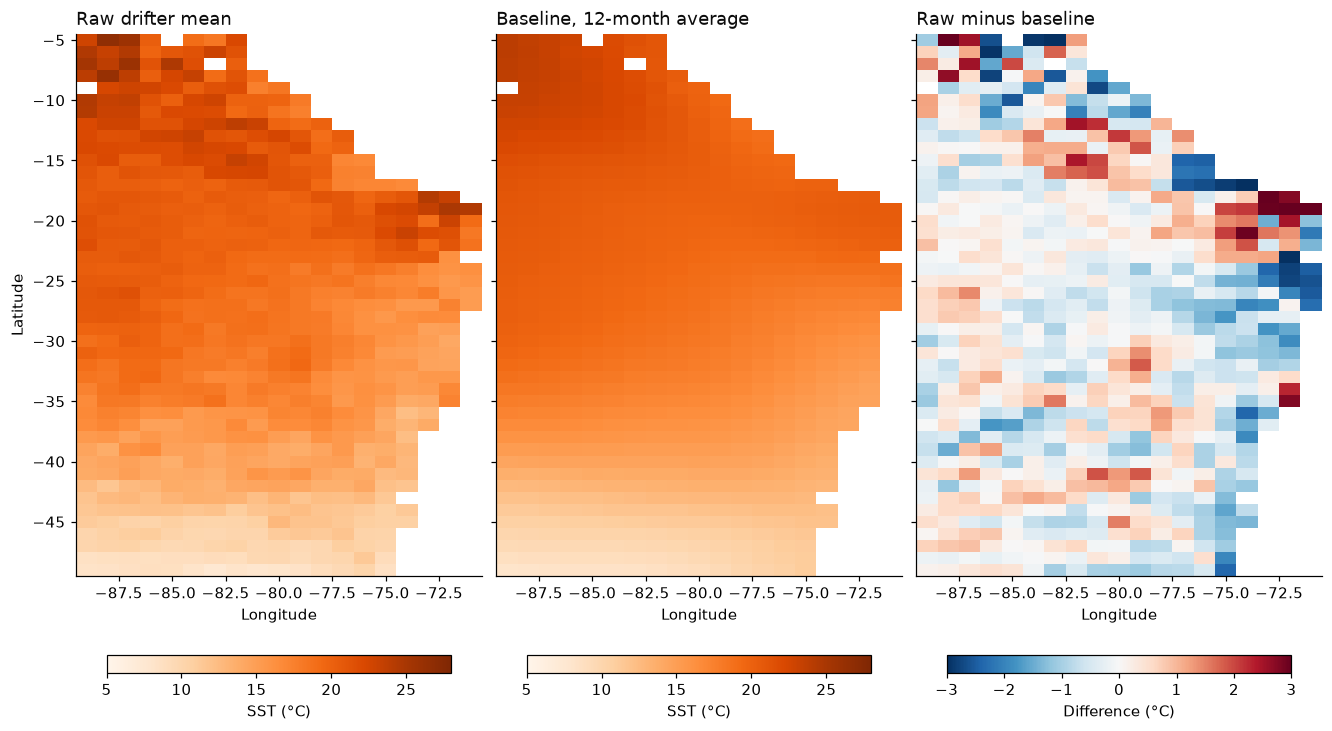

In [53]:
# Check the baseline's annual average against the raw 1-degree mean map
grid = (df.assign(cell_lat=np.floor(df["lat"]), cell_lon=np.floor(df["lon"]))
          .groupby(["cell_lat", "cell_lon"])
          .agg(lat=("lat", "mean"), lon=("lon", "mean"), raw=("sst_degC", "mean")).reset_index())
grid["baseline"] = np.mean([predict(beta_full, grid["lat"].to_numpy(), grid["lon"].to_numpy(),
                                    np.full(len(grid), d)) for d in mid_month_doy], axis=0)
grid["difference"] = grid["raw"] - grid["baseline"]
print(f"Correlation {grid['raw'].corr(grid['baseline']):.3f}; "
      f"RMS difference {np.sqrt((grid['difference'] ** 2).mean()):.2f} C")

panels = [("raw", "Raw drifter mean", "Oranges", 5, 28, "SST (°C)"),
          ("baseline", "Baseline, 12-month average", "Oranges", 5, 28, "SST (°C)"),
          ("difference", "Raw minus baseline", "RdBu_r", -3, 3, "Difference (°C)")]
fig, axes = plt.subplots(1, 3, figsize=(12, 6.5), sharex=True, sharey=True, constrained_layout=True)
for ax, (col, title, cmap, vmin, vmax, label) in zip(axes, panels):
    surface = grid.pivot(index="cell_lat", columns="cell_lon", values=col)
    mesh = ax.pcolormesh(surface.columns, surface.index, surface.to_numpy(), cmap=cmap, vmin=vmin, vmax=vmax,
                         shading="nearest")
    ax.set_title(title, loc="left", color=INK)
    ax.set_xlabel("Longitude")
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.colorbar(mesh, ax=ax, label=label, orientation="horizontal", shrink=0.85)
axes[0].set_ylabel("Latitude")
plt.show()


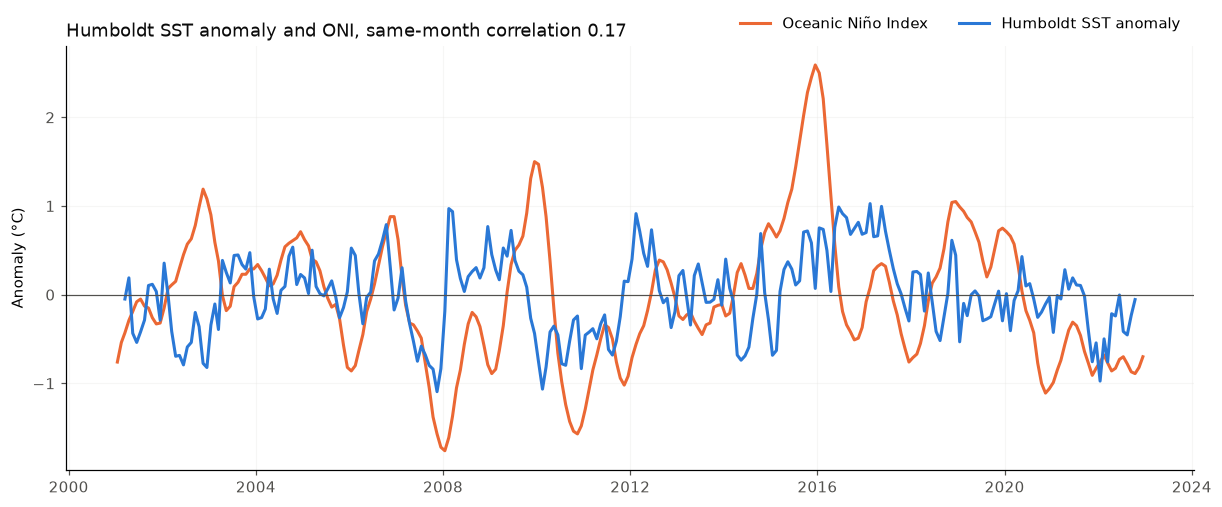

In [54]:
# Figure: regional SST anomaly against the Oceanic Niño Index, both in degrees C on one axis
same_month_corr = sst_monthly["sst_anom"].corr(sst_monthly["oni"])

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ax.plot(m["date"], m["oni"], color=ORANGE, lw=2, label="Oceanic Niño Index")
ax.plot(m["date"], m["sst_anom"], color=BLUE, lw=2, label="Humboldt SST anomaly")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Anomaly (°C)")
ax.set_title(f"Humboldt SST anomaly and ONI, same-month correlation {same_month_corr:.2f}", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)
ax.grid(True, color=GRID, lw=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
fig.savefig("sst_vs_oni.png", dpi=200)
plt.show()


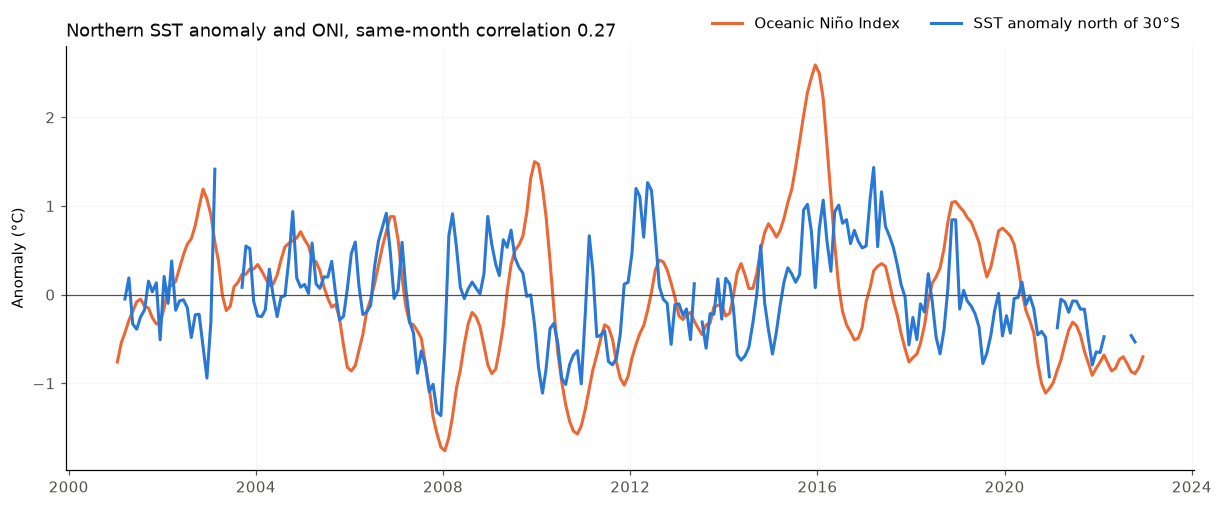

In [55]:
# Figure: SST anomaly north of the split against the Oceanic Niño Index, both in degrees C on one axis
north_corr = sst_monthly["sst_anom_north"].corr(sst_monthly["oni"])

fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
ax.plot(m["date"], m["oni"], color=ORANGE, lw=2, label="Oceanic Niño Index")
ax.plot(m["date"], m["sst_anom_north"], color=BLUE, lw=2, label=f"SST anomaly north of {abs(NORTH_SOUTH_SPLIT)}°S")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_ylabel("Anomaly (°C)")
ax.set_title(f"Northern SST anomaly and ONI, same-month correlation {north_corr:.2f}", loc="left", color=INK)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncols=2)
ax.grid(True, color=GRID, lw=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED)
fig.savefig("sst_north_vs_oni.png", dpi=200)
plt.show()


               type    start      end  months
0   Coastal El Niño  2002-03  2002-05       3
1   Coastal El Niño  2002-10  2002-12       3
2   Coastal El Niño  2006-08  2007-01       6
3   Coastal La Niña  2007-09  2007-12       4
4   Coastal El Niño  2008-06  2008-10       5
5   Coastal El Niño  2009-05  2009-09       5
6   Coastal La Niña  2010-08  2010-12       5
7   Coastal El Niño  2012-04  2012-07       4
8   Coastal La Niña  2013-05  2013-08       4
9   Coastal El Niño  2014-05  2014-10       6
10  Coastal El Niño  2015-04  2016-06      15
11  Coastal El Niño  2016-08  2016-10       3
12  Coastal El Niño  2016-12  2017-04       5
13  Coastal El Niño  2018-11  2019-03       5
14  Coastal La Niña  2022-03  2022-07       5
15  Coastal La Niña  2022-09  2022-11       3


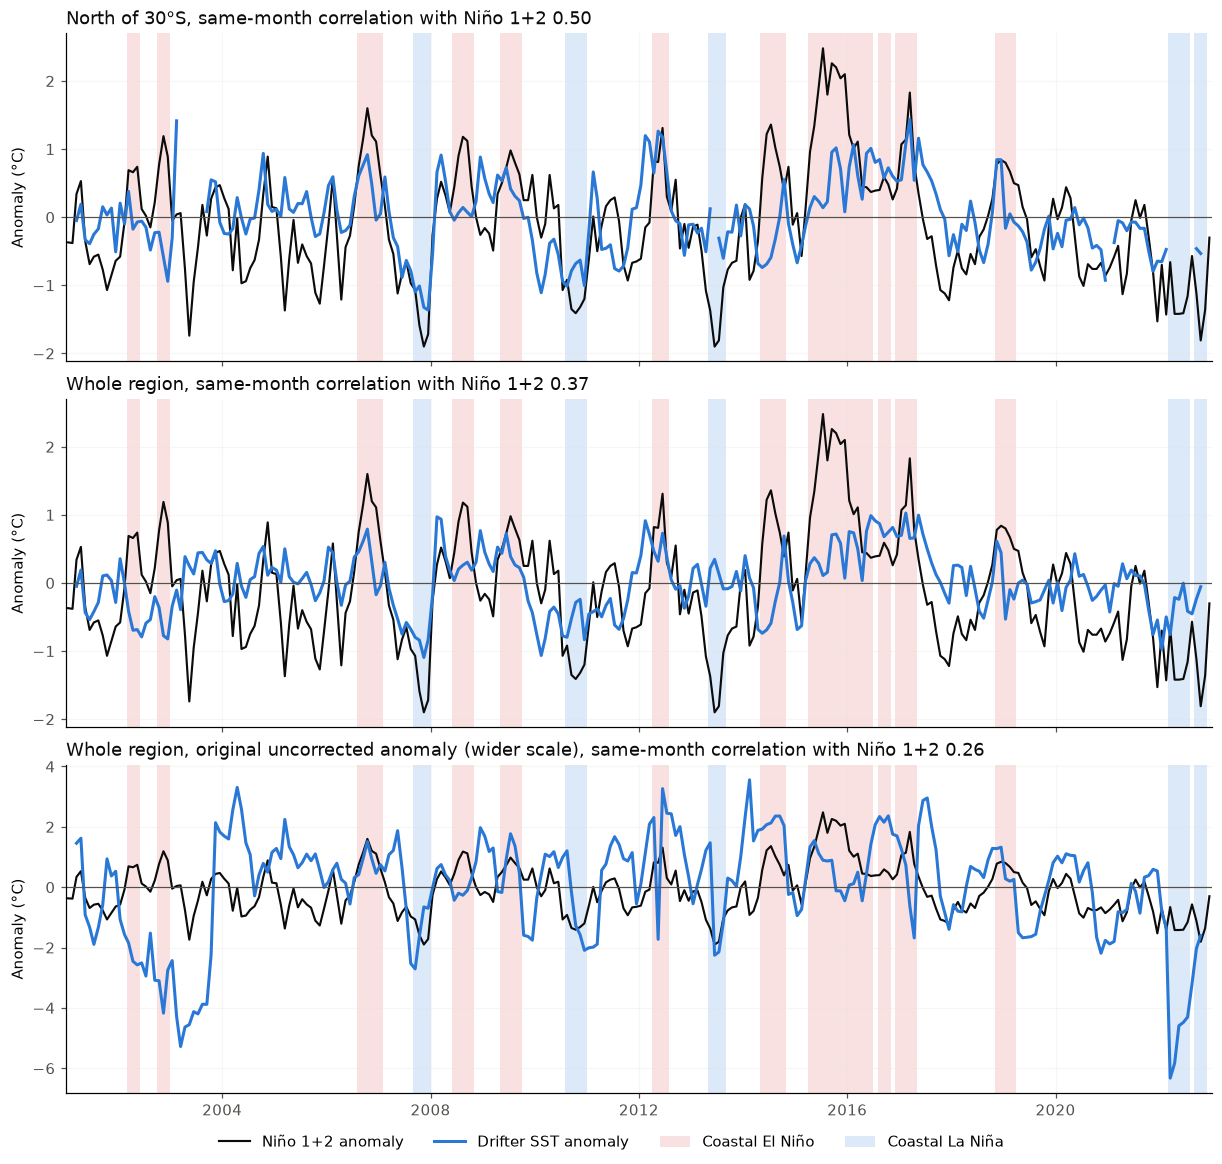

In [56]:
# Figure: north and whole-region SST anomalies against Niño 1+2, the index for waters off Peru and Ecuador
# sstoi.indices is NOAA CPC's monthly Niño SST file: https://www.cpc.ncep.noaa.gov/data/indices/sstoi.indices
RED = "#e34948"
COASTAL_WARM, COASTAL_COLD = 0.4, -1.0   # thresholds based on Peru's coastal El Niño index (ICEN)
COASTAL_MIN_MONTHS = 3

nino = pd.read_csv("sstoi.indices", sep=r"\s+", skiprows=1,
                   names=["year", "month", "nino12", "nino12_anom", "nino3", "nino3_anom",
                          "nino4", "nino4_anom", "nino34", "nino34_anom"])
sst_monthly["nino12"] = nino.set_index(["year", "month"])["nino12_anom"].reindex(sst_monthly.index)
m = sst_monthly

# A coastal event is a run of at least 3 months with the 3-month mean of Niño 1+2 past the threshold
nino12_all = pd.Series(nino["nino12_anom"].to_numpy(),
                       index=pd.PeriodIndex.from_fields(year=nino["year"], month=nino["month"], freq="M"))
nino12_smooth = nino12_all.rolling(3, center=True).mean()


def coastal_events(active, kind):
    run_id = (active != active.shift()).cumsum()
    runs = [run.index for _, run in active[active].groupby(run_id[active]) if len(run) >= COASTAL_MIN_MONTHS]
    return [{"type": kind, "start": r[0], "end": r[-1], "months": len(r)} for r in runs]


coastal = pd.DataFrame(coastal_events(nino12_smooth >= COASTAL_WARM, "Coastal El Niño")
                       + coastal_events(nino12_smooth <= COASTAL_COLD, "Coastal La Niña"))
coastal = coastal[(coastal["end"] >= pd.Period("2001-01")) & (coastal["start"] <= pd.Period("2022-12"))]
coastal = coastal.sort_values("start").reset_index(drop=True)
print(coastal.to_string())

# The original anomaly: the simple monthly mean with only the seasonal cycle removed
sst_monthly["sst_simple_anom"] = deseason(sst_monthly["sst_simple"])

panels = [("sst_anom_north", f"North of {abs(NORTH_SOUTH_SPLIT)}°S"), ("sst_anom", "Whole region"),
          ("sst_simple_anom", "Whole region, original uncorrected anomaly (wider scale)")]
fig, axes = plt.subplots(3, 1, figsize=(11, 10.5), sharex=True, constrained_layout=True)
for ax, (column, label) in zip(axes, panels):
    for e in coastal.itertuples():
        ax.axvspan(e.start.start_time, e.end.end_time, linewidth=0, alpha=0.16,
                   color=RED if e.type == "Coastal El Niño" else BLUE)
    ax.plot(m["date"], m["nino12"], color=INK, lw=1.4, label="Niño 1+2 anomaly")
    ax.plot(m["date"], m[column], color=BLUE, lw=2, label="Drifter SST anomaly")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_ylabel("Anomaly (°C)")
    ax.set_title(f"{label}, same-month correlation with Niño 1+2 {m[column].corr(m['nino12']):.2f}", loc="left", color=INK)
    ax.grid(True, color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
lines, names = axes[0].get_legend_handles_labels()
shades = [plt.Rectangle((0, 0), 1, 1, color=RED, alpha=0.16, linewidth=0),
          plt.Rectangle((0, 0), 1, 1, color=BLUE, alpha=0.16, linewidth=0)]
fig.legend(lines + shades, names + ["Coastal El Niño", "Coastal La Niña"], frameon=False,
           loc="outside lower center", ncols=4)
axes[2].set_xlim(pd.Timestamp("2001-01-01"), pd.Timestamp("2023-01-01"))
axes[1].set_ylim(axes[0].get_ylim())
fig.savefig("sst_vs_nino12.png", dpi=200)
plt.show()


## Current response to El Niño and La Niña

Drifter velocity gives a direct measure of how the water moves. The method follows the SST work: a seasonal baseline for each velocity component, anomalies for each reading, then area-weighted monthly series.

**Only drogued readings are used.** After a drifter loses its drogue, wind pushes it directly, so its velocity no longer represents the current. About half of the readings are undrogued, and that share changes a lot from year to year.

`vn_anom` is the northward velocity anomaly. The Humboldt flows north, so a negative value means weaker flow. The current core is defined here as 15–40°S, east of 80°W.

In [ ]:
# Velocity baselines from drogued readings only, one year left out at a time
DROGUE_FILE = CACHE / "drogue_lost_date.npy"
if not DROGUE_FILE.exists():
    from clouddrift.datasets import gdp1h
    np.save(DROGUE_FILE, gdp1h()["drogue_lost_date"].values)

drogue_lost = pd.Series(np.load(DROGUE_FILE), index=np.load(CACHE / "id.npy"))
df["drogued"] = df["time"] < df["id"].map(drogue_lost).to_numpy()
print(f"Drogued readings: {df['drogued'].mean():.0%}")

drogued = df[df["drogued"]]
vel_units = (drogued.assign(cell_lat=np.floor(drogued["lat"]), cell_lon=np.floor(drogued["lon"]))
                    .groupby(["cell_lat", "cell_lon", "year", "month"])
                    .agg(lat=("lat", "mean"), lon=("lon", "mean"), doy=("doy", "mean"),
                         ve=("ve", "mean"), vn=("vn", "mean"))
                    .reset_index())
vel_weight = (1 / vel_units.groupby("year")["vn"].transform("size")).to_numpy()
vel_weight = vel_weight * len(vel_units) / vel_weight.sum()

VELOCITIES = ["ve", "vn"]
XtWX_year, XtWy_year = {}, {}
for year in sorted(vel_units["year"].unique()):
    k = (vel_units["year"] == year).to_numpy()
    Xk, wk = design_matrix(vel_units["lat"].to_numpy()[k], vel_units["lon"].to_numpy()[k],
                           vel_units["doy"].to_numpy()[k]), vel_weight[k]
    XtWX_year[year], XtWy_year[year] = (Xk.T * wk) @ Xk, (Xk.T * wk) @ vel_units[VELOCITIES].to_numpy()[k]
XtWX, XtWy = sum(XtWX_year.values()), sum(XtWy_year.values())

for name in ["ve_anom", "vn_anom"]:
    df[name] = np.nan
for year, rows in drogued.groupby("year").indices.items():
    beta = np.linalg.solve(XtWX - XtWX_year[year] + penalty, XtWy - XtWy_year[year])
    labels = drogued.index[rows]
    lat, lon = drogued["lat"].to_numpy()[rows], drogued["lon"].to_numpy()[rows]
    doy = drogued["doy"].to_numpy()[rows].astype(float)
    for i, v in enumerate(VELOCITIES):
        df.loc[labels, f"{v}_anom"] = drogued[v].to_numpy()[rows] - predict(beta[:, i], lat, lon, doy)
del drogued

print(df[["ve_anom", "vn_anom"]].describe().round(3))

In [ ]:
# Monthly velocity series, built the same way as sst_anom
CORE_LAT = (-40, -15)
CORE_EAST_OF = -80


def gridded_monthly(data, column):
    binned = data.assign(cell_lat=np.floor(data["lat"] / CELL_DEG) * CELL_DEG,
                         cell_lon=np.floor(data["lon"] / CELL_DEG) * CELL_DEG)
    c = (binned.groupby(["year", "month", "cell_lat", "cell_lon"])[column]
               .agg(anom="mean", n="size").reset_index())
    c = c[c["n"] >= MIN_READINGS].copy()
    c["area"] = np.cos(np.radians(c["cell_lat"] + CELL_DEG / 2))
    return area_mean(c).reindex(all_months)


good = df[df["drogued"]]
core = good[good["lat"].between(*CORE_LAT) & (good["lon"] > CORE_EAST_OF)]
north_drogued = good[good["lat"] >= NORTH_SOUTH_SPLIT]
sst_monthly["vn_anom_core"] = gridded_monthly(core, "vn_anom")
sst_monthly["ve_anom_core"] = gridded_monthly(core, "ve_anom")
sst_monthly["vn_anom_north"] = gridded_monthly(north_drogued, "vn_anom")
sst_monthly["ve_anom_north"] = gridded_monthly(north_drogued, "ve_anom")
sst_monthly["drogued_share"] = df.groupby(["year", "month"])["drogued"].mean()
del good, core, north_drogued

velocity_columns = ["vn_anom_core", "ve_anom_core", "vn_anom_north", "ve_anom_north"]
print(sst_monthly[velocity_columns].agg(["count", "std"]).round(3))
print(sst_monthly[velocity_columns].corrwith(sst_monthly["nino12"]).round(2).rename("Corr with Niño 1+2, same month"))

## Baseline forecasts once a coastal event is flagged

A coastal El Niño or La Niña is flagged once it has lasted 3 months. At months 3, 4 and 5 we forecast the event's **total length**, its **peak SST anomaly** (north of 30°S, from the drifters) and its **mean northward-velocity anomaly** in the current core. Anomalies are signed so that positive means the expected response. La Niña events are sign-flipped and pooled with El Niño, because 5 La Niña events are too few on their own.

Events are flagged with a **trailing** 3-month mean of Niño 1+2. The centered mean used above looks one month ahead, which a forecast can't do.

With about 16 events, the baseline fits no parameters. It uses the past events that also lasted at least *k* months (its "analogs"):
- **Length:** the median length of the analogs.
- **Peak SST:** the peak so far, plus the median further rise the analogs showed after month *k*.
- **Velocity:** the months so far at their observed mean, and the predicted remaining months at the analogs' mean for those later months.

It is scored against **climatology** (the average of all other events) and **persistence** (the event ends now). Every forecast is leave-one-event-out. Skill = 1 − MAE / MAE of climatology.

**How to read the result.** Length is the hard target: the baseline only just beats climatology. For peak SST the analogs' median further rise is 0, so the drifter SST has usually peaked by the time the event is flagged, and the baseline equals persistence. Velocity skill is high mostly because the months already observed make up much of a short event's mean. This is the bar a real model has to clear.

In [ ]:
# ============================================================================
# BASELINE FORECASTS FOR COASTAL EVENTS, ISSUED 3, 4 AND 5 MONTHS IN
#
# A coastal event is flagged once it has lasted 3 months. At months 3, 4 and 5
# we forecast three things about the whole event:
#   duration   total length in months
#   sst_peak   peak drifter SST anomaly north of 30S (3-month trailing mean, C)
#   vn_mean    mean drifter northward-velocity anomaly in the current core (m/s)
# Anomalies are signed so that positive means the expected response
# (warmer and weaker northward flow in El Niño; the reverse in La Niña).
#
# There are only about 15 events, so the baseline fits no parameters:
#   duration   median length of the past events that also lasted at least k months
#   sst_peak   peak so far + median further rise those past events showed after month k
#   vn_mean    months so far at their observed mean, plus the predicted remaining
#              months at the past events' mean for their months after k
# Two references show whether the baseline adds anything:
#   climatology  mean of all other events, ignoring that this one has lasted k months
#   persistence  the event ends now: duration k, peak = peak so far, vn = mean so far
# Every forecast is leave-one-event-out: an event is never in its own analog set.
# ============================================================================
FORECAST_MONTHS = [3, 4, 5]
TARGETS = ["duration", "sst_peak", "vn_mean"]
METHODS = ["climatology", "persistence", "baseline"]
N_BOOT = 2000

# Monthly series indexed by month, so event windows can be sliced by date
tracked = sst_monthly.set_index(pd.PeriodIndex(sst_monthly["date"], freq="M"))

# Real-time flag: a TRAILING 3-month mean, so a forecast at month k uses data up to month k only.
# (The centered mean used for the `coastal` table looks one month ahead.)
nino12_trailing = nino12_all.rolling(3).mean()
rt_events = pd.DataFrame(coastal_events(nino12_trailing >= COASTAL_WARM, "Coastal El Niño")
                         + coastal_events(nino12_trailing <= COASTAL_COLD, "Coastal La Niña"))
# Keep events that fall entirely inside the drifter record
rt_events = rt_events[(rt_events["start"] >= tracked.index[0]) & (rt_events["end"] <= tracked.index[-1])]
rt_events = rt_events.sort_values("start").reset_index(drop=True)

sst_trailing = tracked["sst_anom_north"].rolling(3, min_periods=2).mean()
vn_monthly = tracked["vn_anom_core"]


def nanmax(x):
    x = np.asarray(x, dtype=float)
    return np.nan if np.isnan(x).all() else np.nanmax(x)


def nanmean(x):
    x = np.asarray(x, dtype=float)
    return np.nan if np.isnan(x).all() else np.nanmean(x)


def event_record(e):
    sign = 1 if e.type == "Coastal El Niño" else -1
    months = pd.period_range(e.start, e.end, freq="M")
    sst = sign * sst_trailing.reindex(months).to_numpy()
    vn = -sign * vn_monthly.reindex(months).to_numpy()
    return {"type": e.type, "start": e.start, "duration": e.months, "sst": sst, "vn": vn,
            "sst_peak": nanmax(sst), "vn_mean": nanmean(vn)}


records = [event_record(e) for e in rt_events.itertuples()]


def forecast(train, test, k):
    """All three methods' forecasts for `test`, issued at month k, using only `train`."""
    sst_so_far, vn_so_far = nanmax(test["sst"][:k]), nanmean(test["vn"][:k])
    clim = {t: nanmean([r[t] for r in train]) for t in TARGETS}

    analogs = [r for r in train if r["duration"] >= k]
    duration = float(np.median([r["duration"] for r in analogs]))
    rises = np.array([r["sst_peak"] - nanmax(r["sst"][:k]) for r in analogs])
    rise = np.median(rises[~np.isnan(rises)]) if (~np.isnan(rises)).any() else 0.0
    later_vn = nanmean([nanmean(r["vn"][k:]) for r in analogs if r["duration"] > k])
    remaining = max(duration - k, 0.0)
    if np.isnan(vn_so_far):
        vn_base = later_vn
    elif remaining == 0 or np.isnan(later_vn):
        vn_base = vn_so_far
    else:
        vn_base = (k * vn_so_far + remaining * later_vn) / (k + remaining)

    return {
        "climatology": clim,
        "persistence": {"duration": k, "sst_peak": sst_so_far, "vn_mean": vn_so_far},
        "baseline": {"duration": duration, "sst_peak": sst_so_far + rise, "vn_mean": vn_base},
    }


def run_forecasts(pool):
    rows = []
    for i, test in enumerate(pool):
        train = pool[:i] + pool[i + 1:]
        for k in FORECAST_MONTHS:
            if test["duration"] < k:      # already over, nothing to forecast
                continue
            f = forecast(train, test, k)
            for t in TARGETS:
                rows.append({"start": test["start"], "type": test["type"], "k": k, "target": t,
                             "observed": test[t], **{m: f[m][t] for m in METHODS}})
    out = pd.DataFrame(rows)
    # Score each target only where every method and the observation exist
    return out.dropna(subset=["observed"] + METHODS)


def skill_table(fc):
    rows = []
    for (k, t), g in fc.groupby(["k", "target"]):
        err = {m: (g[m] - g["observed"]).abs().to_numpy() for m in METHODS}
        picks = rng.integers(0, len(g), (N_BOOT, len(g)))
        clim_boot = err["climatology"][picks].mean(axis=1)
        for m in METHODS:
            boot = 1 - err[m][picks].mean(axis=1) / clim_boot
            rows.append({"k": k, "target": t, "method": m, "n": len(g), "mae": err[m].mean(),
                         "skill": 1 - err[m].mean() / err["climatology"].mean(),
                         "skill_lo": np.nanquantile(boot, 0.025), "skill_hi": np.nanquantile(boot, 0.975)})
    return pd.DataFrame(rows)


rng = np.random.default_rng(0)
pools = {"Pooled (La Niña sign-flipped)": records,
         "El Niño only": [r for r in records if r["type"] == "Coastal El Niño"]}
forecasts = {name: run_forecasts(pool) for name, pool in pools.items()}
skills = {name: skill_table(fc) for name, fc in forecasts.items()}

print(rt_events.to_string())
print(f"\nEvents still running at month k: "
      + ", ".join(f"k={k}: {sum(r['duration'] >= k for r in records)}" for k in FORECAST_MONTHS))
for name, s in skills.items():
    print(f"\n{name}: mean absolute error, and skill vs climatology (1 = perfect, 0 = no better, <0 worse)")
    table = s.pivot_table(index=["target", "k"], columns="method", values=["mae", "skill"])
    table.insert(0, "n", s.groupby(["target", "k"])["n"].first())
    print(table.round(3).to_string())

# Figure: skill against forecast month, one panel per target (pooled events)
s = skills["Pooled (La Niña sign-flipped)"]
titles = {"duration": "Event length", "sst_peak": "Peak SST anomaly", "vn_mean": "Mean velocity anomaly"}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True, constrained_layout=True)
for ax, t in zip(axes, TARGETS):
    for m, color, offset in [("persistence", ORANGE, -0.06), ("baseline", BLUE, 0.06)]:
        g = s[(s["target"] == t) & (s["method"] == m)].sort_values("k")
        x = g["k"] + offset
        ax.vlines(x, g["skill_lo"], g["skill_hi"], color=color, lw=2, alpha=0.35)
        ax.plot(x, g["skill"], color=color, lw=2, marker="o", ms=8, mec="white", mew=2, label=m.capitalize())
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.text(2.8, -0.04, "Climatology", color=MUTED, va="top", ha="left", fontsize=8)
    n = s[(s["target"] == t) & (s["method"] == "baseline")].sort_values("k")["n"].tolist()
    ax.set_title(f"{titles[t]}  (n = {', '.join(map(str, n))})", loc="left", color=INK, fontsize=10)
    ax.set_xticks(FORECAST_MONTHS)
    ax.set_xlim(2.75, 5.25)
    ax.set_xlabel("Forecast issued at event month")
    ax.grid(True, color=GRID, lw=0.7)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("Skill vs climatology")
axes[0].set_ylim(max(axes[0].get_ylim()[0], -3), 1)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="outside lower center", ncols=2)
fig.savefig("fig3_forecast_skill.png", dpi=200)
plt.show()
